# Zimbabwe Healthcare Accessibility Explorer
## Notebook 5 — Validation, Findings and Export
**Author: Tinashe Clifford Makandise**

### Purpose
Validate the saved nearest-facility results, reconcile national and district indicators, examine geometric sensitivity to cell-centre representation, and export compact application data plus a final findings report.

Run Notebooks 1–4 first. Save this notebook beside them in `notebooks/` and select **Run All** in the same environment. No additional packages are required beyond those already used. This notebook uses saved distances rather than rerunning the full nearest-search algorithm.

Validation here concerns numerical and processing consistency. It cannot verify present-day facility operation, missing providers, population-model accuracy, road travel time, capacity or service quality. Historical facility records and 2020 population estimates remain a mixed-period exploratory study.

In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from pyproj import Geod
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROCESSED, REPORTS = ROOT / "data/raw", ROOT / "data/processed", ROOT / "reports"
TABLES, MAPS, APP_DATA = ROOT / "outputs/tables", ROOT / "outputs/maps", ROOT / "data/app"
for folder in [TABLES, MAPS, REPORTS, APP_DATA]:
    folder.mkdir(parents=True, exist_ok=True)
prep = json.loads((REPORTS / "02_preparation_report.json").read_text(encoding="utf-8"))
analysis = json.loads((REPORTS / "04_accessibility_report.json").read_text(encoding="utf-8"))
input_hashes = {}
for name, expected in {**analysis["input_sha256"], **analysis["output_sha256"]}.items():
    path = PROCESSED / name
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}; run Notebook 4 and its prerequisites first.")
    input_hashes[name] = hashlib.sha256(path.read_bytes()).hexdigest()
    assert input_hashes[name] == expected, f"Upstream file changed: {name}"
access = pd.read_csv(PROCESSED / "population_accessibility.csv", dtype={"adm2_pcode": "string", "nearest_facility_district": "string"})
facilities = gpd.read_file(PROCESSED / "facilities_prepared.geojson").sort_values("facility_id").reset_index(drop=True)
districts = gpd.read_file(PROCESSED / "district_accessibility.geojson")
assert access.cell_id.is_unique and facilities.facility_id.is_unique and districts.adm2_pcode.is_unique
assert np.isfinite(access[["population", "distance_km", "latitude", "longitude"]]).all().all()
assert (access.population > 0).all() and (access.distance_km >= 0).all()
assert set(access.nearest_facility_id).issubset(set(facilities.facility_id))
print(f"Verified saved inputs: {len(access):,} population centres, {len(facilities):,} facility locations and {len(districts)} district records.")

Verified saved inputs: 479,031 population centres, 1,201 facility locations and 91 district records.


### 1. Check nearest matches on a broader, targeted sample
Combine a seeded random sample with the most distant cells, the most populated cells and cells closest to each threshold. Compute exhaustive WGS84 geodesic distances to all facilities for each selected centre, bypassing Notebook 4's spatial-index candidate selection.

This checks the search and exported nearest IDs, using the same established geodesic calculation engine. A separate spherical haversine calculation is included as an approximate unit/order sanity check; it is not the authoritative distance because Earth is not a perfect sphere.

In [2]:
geod = Geod(ellps="WGS84")
lon_f = facilities.longitude.to_numpy(dtype=float)
lat_f = facilities.latitude.to_numpy(dtype=float)
rng = np.random.default_rng(2026)
selected = set(rng.choice(len(access), size=min(100, len(access)), replace=False).tolist())
selected.update(access.nlargest(10, "distance_km").index.tolist())
selected.update(access.nlargest(10, "population").index.tolist())
for threshold in [5, 10, 20]:
    selected.update((access.distance_km - threshold).abs().nsmallest(10).index.tolist())
checks = []
for index in sorted(selected):
    row = access.iloc[index]
    _, _, all_m = geod.inv(np.full(len(facilities), row.longitude), np.full(len(facilities), row.latitude), lon_f, lat_f)
    nearest = int(np.argmin(all_m))
    error_m = abs(float(all_m[nearest]) - row.distance_km * 1000)
    assert error_m < 1e-5
    assert facilities.facility_id.iloc[nearest] == row.nearest_facility_id
    lat1, lat2 = np.deg2rad([row.latitude, lat_f[nearest]])
    delta_lat = lat2-lat1
    delta_lon = np.deg2rad(lon_f[nearest]-row.longitude)
    h = np.sin(delta_lat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(delta_lon/2)**2
    spherical_km = 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))
    relative_difference = abs(spherical_km - row.distance_km) / max(row.distance_km, 1e-12)
    assert relative_difference < .006
    checks.append({"cell_id": int(row.cell_id), "distance_km": float(row.distance_km),
                   "absolute_exhaustive_error_m": error_m, "haversine_relative_difference": float(relative_difference)})
validation_table = pd.DataFrame(checks)
validation_table.to_csv(TABLES / "05_exhaustive_distance_validation.csv", index=False)
print("Exhaustive nearest-facility comparisons passed:", len(checks))
print("Maximum distance error (m):", validation_table.absolute_exhaustive_error_m.max())
print("Maximum approximate spherical difference (%):", validation_table.haversine_relative_difference.max() * 100)

Exhaustive nearest-facility comparisons passed: 150
Maximum distance error (m): 7.275957614183426e-12
Maximum approximate spherical difference (%): 0.470705984269362


### 2. Reconcile cell-level results, district summaries and national metrics
Recompute from saved cell rows rather than trusting report totals. Confirm threshold counts are monotonic and remain within each population denominator. Preserve unassigned-district population separately if present. Weighted district means must aggregate back to the national mean when all population is assigned.

These checks detect processing inconsistencies but do not establish empirical accuracy of the underlying sources.

In [3]:
population_total = float(access.population.sum())
mean_distance = float(np.average(access.distance_km, weights=access.population))
np.testing.assert_allclose(population_total, analysis["national_metrics"]["population_denominator"], rtol=1e-10)
np.testing.assert_allclose(mean_distance, analysis["national_metrics"]["weighted_mean_distance_km"], rtol=1e-10)
np.testing.assert_allclose(population_total, prep["population_audit"]["inside_country_population"], rtol=1e-10)
assigned = access.adm2_pcode.notna()
recomputed_population = access.loc[assigned].groupby("adm2_pcode").population.sum()
recomputed_numerator = (access.loc[assigned, "population"] * access.loc[assigned, "distance_km"]).groupby(access.loc[assigned, "adm2_pcode"]).sum()
district_lookup = districts.set_index("adm2_pcode")
for code_value in recomputed_population.index:
    np.testing.assert_allclose(recomputed_population.loc[code_value], district_lookup.loc[code_value, "population_estimate"], rtol=1e-10)
    np.testing.assert_allclose(recomputed_numerator.loc[code_value]/recomputed_population.loc[code_value], district_lookup.loc[code_value, "weighted_mean_distance_km"], rtol=1e-10)
threshold_check = []
for threshold in [5, 10, 20]:
    total_beyond = float(access.loc[access.distance_km > threshold, "population"].sum())
    np.testing.assert_allclose(total_beyond, analysis["national_metrics"][f"population_beyond_{threshold}km"], rtol=1e-10)
    by_district = access.loc[assigned & access.distance_km.gt(threshold)].groupby("adm2_pcode").population.sum().reindex(recomputed_population.index, fill_value=0)
    np.testing.assert_allclose(by_district, district_lookup.loc[by_district.index, f"population_beyond_{threshold}km"], rtol=1e-10, atol=1e-6)
    assert 0 <= total_beyond <= population_total
    threshold_check.append(total_beyond)
assert np.all(np.diff(threshold_check) <= 0)
np.testing.assert_allclose(districts.population_estimate.sum(), access.loc[assigned, "population"].sum(), rtol=1e-10)
if assigned.all():
    np.testing.assert_allclose(np.average(districts.weighted_mean_distance_km, weights=districts.population_estimate), mean_distance, rtol=1e-10)
print("Population, district means and all three threshold summaries reconcile.")
print("Unassigned district population:", float(access.loc[~assigned, "population"].sum()))

Population, district means and all three threshold summaries reconcile.
Unassigned district population: 0.0


### 3. Examine cell-location sensitivity with a conservative geometric envelope
A resident is not necessarily at the grid-cell centre. For a fixed facility set, nearest-facility distance changes by no more than the distance a location moves (triangle inequality).

For the native geographic rectangle, construct a deliberately conservative within-cell displacement bound: travel along a meridian and then along a parallel from the centre to a possible position. Bound both path lengths using the maximum WGS84 curvature radius, rounded upward, and the half-cell angular widths. This is larger than the half-diagonal and covers every point in the native cell under the zero-height ellipsoid assumption.

If centre distance is `d` and displacement bound is `r`, possible nearest-facility distances lie within `[max(0, d-r), d+r]`. Population certainly beyond a threshold has `d-r > threshold`; population possibly beyond has `d+r > threshold`. This yields conservative population envelopes with unknown within-cell locations.

**These are not confidence intervals.** They cover positional approximation only, holding the same facilities and population counts fixed. They do not account for omitted facilities, source-coordinate errors, cell population errors, residents outside the country in straddling cells, or the population previously excluded by the national-centre rule.

Conservative maximum within-cell displacement bound: 0.931 km
 threshold_km  conservative_minimum_percent_beyond  centre_based_percent_beyond  conservative_maximum_percent_beyond  population_in_positional_ambiguity_band
            5                               41.997                       49.496                               57.639                              2323168.792
           10                               15.006                       18.356                               22.390                              1096653.786
           20                                2.543                        2.902                                3.326                               116221.904


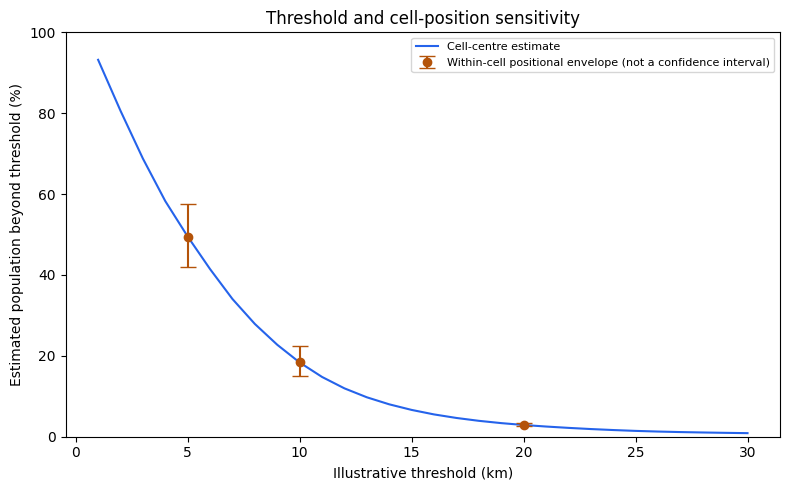

In [4]:
raster_path = RAW / "zwe_ppp_2020_1km_Aggregated_UNadj.tif"
assert hashlib.sha256(raster_path.read_bytes()).hexdigest() == prep["input_sha256"][raster_path.name]
with rasterio.open(raster_path) as src:
    assert src.crs.to_epsg() == 4326 and src.transform.b == 0 and src.transform.d == 0
    half_lon_degrees, half_lat_degrees = abs(src.res[0])/2, abs(src.res[1])/2
max_curvature_radius_m = np.ceil(geod.a / np.sqrt(1 - geod.es))
cell_displacement_km = max_curvature_radius_m * (np.deg2rad(half_lon_degrees) + np.deg2rad(half_lat_degrees)) / 1000
lower_distance = np.maximum(0, access.distance_km.to_numpy() - cell_displacement_km)
upper_distance = access.distance_km.to_numpy() + cell_displacement_km
sensitivity_rows = []
for threshold in [5, 10, 20]:
    definitely = float(access.loc[lower_distance > threshold, "population"].sum())
    centre_based = float(access.loc[access.distance_km > threshold, "population"].sum())
    possibly = float(access.loc[upper_distance > threshold, "population"].sum())
    assert definitely <= centre_based + 1e-6 <= possibly + 1e-6
    sensitivity_rows.append({"threshold_km": threshold,
                             "conservative_minimum_percent_beyond": definitely/population_total*100,
                             "centre_based_percent_beyond": centre_based/population_total*100,
                             "conservative_maximum_percent_beyond": possibly/population_total*100,
                             "population_in_positional_ambiguity_band": possibly-definitely})
sensitivity = pd.DataFrame(sensitivity_rows)
print(f"Conservative maximum within-cell displacement bound: {cell_displacement_km:.3f} km")
print(sensitivity.round(3).to_string(index=False))
sensitivity.to_csv(TABLES / "05_cell_position_sensitivity.csv", index=False)
threshold_curve = pd.DataFrame({"threshold_km": np.arange(1, 31)})
threshold_curve["percent_beyond"] = [access.loc[access.distance_km > t, "population"].sum()/population_total*100 for t in threshold_curve.threshold_km]
assert (np.diff(threshold_curve.percent_beyond) <= 0).all()
threshold_curve.to_csv(TABLES / "05_threshold_curve.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(threshold_curve.threshold_km, threshold_curve.percent_beyond, label="Cell-centre estimate", color="#2563eb")
y = sensitivity.centre_based_percent_beyond.to_numpy()
yerr = np.vstack([y-sensitivity.conservative_minimum_percent_beyond.to_numpy(), sensitivity.conservative_maximum_percent_beyond.to_numpy()-y])
ax.errorbar(sensitivity.threshold_km, y, yerr=yerr, fmt="o", capsize=6, color="#b45309", label="Within-cell positional envelope (not a confidence interval)")
ax.set(xlabel="Illustrative threshold (km)", ylabel="Estimated population beyond threshold (%)", ylim=(0,100), title="Threshold and cell-position sensitivity")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(MAPS / "05_threshold_and_position_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Produce compact district and facility exports for the application
The app will load precomputed summaries. Preserve analytical district geometries upstream; simplify only a separate display copy by 25 metres in an equal-area projected CRS. Validate display geometries and report area change. Independently simplified polygons can show small visual gaps/overlaps at shared borders, so display geometry must never be used to assign locations or recompute metrics.

Keep the full facility inventory for display, including flags for source-province disagreements. Facility-type filters in the future app should be labelled as display filters unless accessibility is separately recalculated for each type. The exported indicators always refer to the complete prepared facility set.

In [5]:
district_display = districts.copy()
projected = districts.to_crs(6933)
simplified_geometry = projected.geometry.simplify(tolerance=25, preserve_topology=True)
assert simplified_geometry.is_valid.all() and (~simplified_geometry.is_empty).all()
area_change_fraction = (simplified_geometry.area - projected.area).abs() / projected.area
assert area_change_fraction.max() < .01
simplified = gpd.GeoSeries(simplified_geometry, crs=6933).to_crs(4326)
district_display.geometry = simplified
full_district_path = PROCESSED / "district_accessibility.geojson"
display_path = APP_DATA / "districts_display.geojson"
district_display.to_file(display_path, driver="GeoJSON")
districts.drop(columns="geometry").to_csv(APP_DATA / "district_summary.csv", index=False)
facility_columns = ["facility_id", "facility_name", "facility_type", "ownership", "latitude", "longitude", "adm2_pcode", "adm2_name", "adm1_name", "province_disagreement", "geometry"]
facilities[facility_columns].to_file(APP_DATA / "facilities.geojson", driver="GeoJSON")
print("Analytical boundary file MiB:", round(full_district_path.stat().st_size/1024**2, 2))
print("Display boundary file MiB:", round(display_path.stat().st_size/1024**2, 2))
print("Maximum per-district absolute area change (%):", round(float(area_change_fraction.max()*100), 4))

Analytical boundary file MiB: 16.55
Display boundary file MiB: 2.15
Maximum per-district absolute area change (%): 0.2269


### 5. Export compressed cell data and validate round trips
Retain every analysed cell for threshold queries; do not use a map sample to calculate totals. Export just the fields needed by the app as a compressed CSV. Re-read it to verify IDs, population and distances. This representation is smaller than the full analysis table but retains native cell resolution and full numerical precision.

The app can limit displayed points for performance if that limit is explicit. Metrics must still use all relevant cells. No live nearest-facility recalculation or modelling of alternative facility sets is implied.

In [6]:
cell_columns = ["cell_id", "raster_row", "raster_col", "longitude", "latitude", "population", "adm2_pcode", "distance_km", "nearest_facility_id", "nearest_in_other_district"]
cell_path = APP_DATA / "population_accessibility.csv.gz"
access[cell_columns].to_csv(cell_path, index=False, compression={"method": "gzip", "mtime": 0})
restored = pd.read_csv(cell_path, dtype={"adm2_pcode": "string"})
assert restored.cell_id.is_unique and np.array_equal(restored.cell_id, access.cell_id)
np.testing.assert_allclose(restored.population, access.population, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(restored.distance_km, access.distance_km, rtol=1e-12, atol=1e-12)
for threshold in [5,10,20]:
    np.testing.assert_allclose(restored.loc[restored.distance_km > threshold, "population"].sum(), analysis["national_metrics"][f"population_beyond_{threshold}km"], rtol=1e-10)
restored_districts = pd.read_csv(APP_DATA / "district_summary.csv")
assert set(restored_districts.adm2_pcode) == set(districts.adm2_pcode)
np.testing.assert_allclose(restored_districts.population_estimate.sum(), population_total, rtol=1e-10)
print("Cell export MiB:", round(cell_path.stat().st_size/1024**2, 2))
print("Round-trip cell and summary checks passed; no map sampling used for calculations.")

Cell export MiB: 14.68
Round-trip cell and summary checks passed; no map sampling used for calculations.


### 6. Write the final findings and application metadata
Report results with denominators, source scope and limitations. We identify district indicators as screening evidence, not recommendations to build a facility. Metadata records all export checksums, the distance definition, threshold conventions and caveats needed by the interface.

The positional envelope is one limited sensitivity analysis. We have not established sensitivity to a different population model or a truly coarser grid, and no quantitative correction is possible for the 35 unlocated facilities without reliable additional coordinates. These remain documented limitations rather than invented certainty.

In [7]:
national = analysis["national_metrics"]
(APP_DATA / "national_metrics.json").write_text(json.dumps(national, indent=2), encoding="utf-8")
sensitivity.to_csv(APP_DATA / "position_sensitivity.csv", index=False)
limitations = [
    "Historical facility compilation and 2020 modelled population; not a current operational register.",
    "Incomplete provider coverage, including 35 source records without coordinates; no capacity or quality assessment.",
    "Population placed at approximately 1 km native-cell centres; within-cell envelope covers only positional approximation.",
    "Facilities outside Zimbabwe excluded; international-border distances may be overstated.",
    "Geodesic distances are not road distances or travel times; thresholds are illustrative, not official standards.",
    "Display boundary simplification affects only appearance; use original prepared geometry for analytical assignment.",
]
app_files = ["districts_display.geojson", "district_summary.csv", "facilities.geojson", "population_accessibility.csv.gz", "national_metrics.json", "position_sensitivity.csv"]
metadata = {
    "author": "Tinashe Clifford Makandise", "title": "Zimbabwe Healthcare Accessibility Explorer",
    "status": "validated computational exports; app not yet built",
    "distance_method": "WGS84 ellipsoidal geodesic from native population-cell centre to nearest prepared in-country facility",
    "facility_count": len(facilities), "population_cells": len(access), "districts": len(districts),
    "population_denominator": population_total, "thresholds_km": [5,10,20], "beyond_rule": "strictly greater than threshold",
    "facility_filter_semantics": "Display only; all indicators refer to the full prepared facility set",
    "display_simplification_metres": 25, "display_area_change_max_percent": float(area_change_fraction.max()*100),
    "cell_position_envelope_radius_km": float(cell_displacement_km),
    "validation": {"exhaustive_sample_cells": len(checks), "max_sample_error_m": float(validation_table.absolute_exhaustive_error_m.max()),
                   "cell_round_trip": "passed", "district_national_reconciliation": "passed"},
    "limitations": limitations,
    "sources": [{"name": "Maina et al. (2019) facility data", "url": "https://doi.org/10.6084/m9.figshare.7725374", "license": "CC0 in Figshare data record; cite study https://doi.org/10.1038/s41597-019-0142-2"},
                {"name": "WorldPop Zimbabwe 2020 1 km UN-adjusted counts", "url": "https://hub.worldpop.org/geodata/summary?id=38911", "license": "CC BY 4.0; WorldPop/CIESIN attribution"},
                {"name": "OCHA/HDX Zimbabwe COD-AB boundaries", "url": "https://data.humdata.org/dataset/cod-ab-zwe", "license": "CC BY-IGO; source catalogue"}],
    "input_sha256": input_hashes,
    "app_files_sha256": {name: hashlib.sha256((APP_DATA/name).read_bytes()).hexdigest() for name in app_files},
}
(APP_DATA / "app_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
report_text = f"""# Zimbabwe Healthcare Accessibility — Final Analytical Findings
Author: Tinashe Clifford Makandise

## Question and scope
Which populated areas are relatively far from mapped public-sector facilities? Historical facility locations are combined with 2020 modelled population and OCHA reporting boundaries. This is an exploratory mixed-period analysis, not a current healthcare coverage assessment.

## Data and method
The source workbook contains 1,236 Zimbabwe records. Analysis uses {len(facilities):,} usable in-country coordinates; 35 missing-coordinate records remain in the audit. Two source-province disagreements remain flagged. Population-cell centres inside the national boundary represent {population_total:,.0f} estimated residents across {len(access):,} positive cells. The prior boundary-centre exclusion is {prep['population_audit']['outside_country_centre_population']:,.0f} estimated residents ({prep['population_audit']['outside_country_population_percent']:.3f}% of the original raster population). Facility search crosses district boundaries but excludes other countries.

Nearest distances use WGS84 ellipsoidal geodesics. Indicators are population-weighted; beyond-threshold means strictly greater than the threshold.

## Main results
- Population-weighted mean distance: {national['weighted_mean_distance_km']:.2f} km.
- Population-weighted median: {national['weighted_median_distance_km']:.2f} km.
- Population-weighted 90th percentile: {national['weighted_p90_distance_km']:.2f} km.
- Beyond 5 km: {national['population_beyond_5km']:,.0f} estimated residents ({national['percent_beyond_5km']:.2f}%).
- Beyond 10 km: {national['population_beyond_10km']:,.0f} estimated residents ({national['percent_beyond_10km']:.2f}%).
- Beyond 20 km: {national['population_beyond_20km']:,.0f} estimated residents ({national['percent_beyond_20km']:.2f}%).
- Nearest facility in another district: {national['nearest_other_district_population_percent']:.2f}% of analysed population.

## Validation and sensitivity
{len(checks)} targeted/random exhaustive nearest-facility checks passed. Saved cell totals, district means and threshold summaries reconcile, and compressed exports reproduce the original metrics. A conservative {cell_displacement_km:.3f} km within-cell displacement bound gives positional threshold envelopes (see outputs/tables/05_cell_position_sensitivity.csv). These are not statistical confidence intervals and do not include facility omission or population-model uncertainty.

## Use and limitations
The findings identify geographic patterns worth investigating. Facility records should be locally verified before planning decisions. Distances do not measure road travel, transport availability, staffing, affordability, capacity or quality. No official access standards, current operational checks, alternate population-model validation or optimal new-facility recommendations are claimed.

## Sources
- Maina et al. (2019), Scientific Data 6:134: https://doi.org/10.1038/s41597-019-0142-2; data https://doi.org/10.6084/m9.figshare.7725374.
- WorldPop/CIESIN Zimbabwe population product: https://hub.worldpop.org/geodata/summary?id=38911; https://doi.org/10.5258/SOTON/WP00671.
- OCHA/HDX Zimbabwe COD-AB: https://data.humdata.org/dataset/cod-ab-zwe.

## Next deliverable
A Streamlit app using precomputed validated data, source attribution and clearly labelled limitations. The app has not yet been built or deployed.
"""
(REPORTS / "final_findings.md").write_text(report_text, encoding="utf-8")
(REPORTS / "05_validation_report.json").write_text(json.dumps({"validation": metadata["validation"], "positional_sensitivity": sensitivity.to_dict("records"), "cell_displacement_bound_km": cell_displacement_km, "input_sha256": input_hashes}, indent=2), encoding="utf-8")
for name, digest in input_hashes.items():
    assert hashlib.sha256((PROCESSED / name).read_bytes()).hexdigest() == digest
print("Final findings report and seven application data files saved. Analytical inputs unchanged.")
print("Next: Build the Streamlit application.")

Final findings report and seven application data files saved. Analytical inputs unchanged.
Next: Build the Streamlit application.


### Completion checklist
- Saved analytical files verified against prior fingerprints.
- Targeted/random exhaustive nearest matches checked.
- Cell, district and national population/threshold totals reconciled.
- Within-cell positional sensitivity reported without treating it as a confidence interval.
- Display-only simplified polygons separated from analytical boundaries.
- Compact cell exports retain all analysed cells and reproduce metrics.
- Final report and application metadata preserve scope, sources and limitations.

**Next: Streamlit app.** Load `data/app/`, show district maps and metrics, allow illustrative threshold queries using full cell data, provide CSV downloads, and keep facility display filtering separate from the precomputed all-facility indicators.